# Student Academic Risk Prediction — Machine Learning Project

**Research problem:** Can student engagement, previous performance, and access-related factors help predict whether a student may be academically at risk?

**Dataset:** `dataset/student_academic_risk_dataset.csv` — a generated, synthetic teaching dataset with 6,008 rows before cleaning. It is not real student data and must not be presented as collected facts about real students. The notebook removes intentionally added duplicate rows and handles intentionally introduced missing values.

**Methods:** dataset inspection and cleaning, exploratory analysis, preprocessing (median/mode imputation, one-hot encoding, standardization), three classification models, 5-fold stratified cross-validation, and final evaluation on a held-out test set.

This workflow follows the supplied ITLML801 notes on dataset relevance/completeness/accuracy, cleaning missing values and duplicates, normalization, categorical encoding, EDA, and comparing supervised classification algorithms. Models used here are Logistic Regression, Decision Tree, and Random Forest.


In [1]:

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42

# The CSV is stored inside a folder named 'dataset'.
CSV_NAME = 'student_academic_risk_dataset.csv'

# Check the current folder and its parent. This supports common VS Code
# project layouts, for example: project/dataset/student_academic_risk_dataset.csv.
_search_roots = [Path.cwd(), Path.cwd().parent, Path('/mnt/data')]
_candidates = []
for root in _search_roots:
    _candidates.extend([
        root / 'dataset' / CSV_NAME,  # preferred location
        root / CSV_NAME,              # fallback if CSV is beside the notebook
        root / 'datasets' / CSV_NAME,
        root / 'data' / CSV_NAME,
    ])

DATA_PATH = next((p.resolve() for p in _candidates if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        f"Could not find '{CSV_NAME}'. Expected it in a folder named 'dataset' "
        f"beside the notebook/project folder. Current working folder: {Path.cwd()}"
    )
print('Dataset found:', DATA_PATH)


Dataset found: D:\Btech\Machine Learning\fistproject\dataset\student_academic_risk_dataset.csv


## 1. Load and understand the dataset
The CSV file is stored in a folder named `dataset`. Keep the folder beside your project/notebook folder. The setup cell checks this location automatically and prints the full path it finds.

In [2]:
df = pd.read_csv(DATA_PATH)
print('Original shape:', df.shape)
display(df.head())
print('\nData types and non-null counts:')
df.info()


Original shape: (6008, 14)


,Student_ID,Age,Gender,Program,Study_Hours_Per_Week,Attendance_Percent,Previous_Average_Score,Assignment_Score,Internet_Access,Part_Time_Work,Financial_Stress,Commute_Minutes,Missed_Deadlines,Academic_Risk
0,STU00001,18,Male,Education,16.0,100.0,70.3,75.9,Yes,No,Medium,42.4,1,Not_At_Risk
1,STU00002,27,Male,IT,17.4,91.4,52.6,47.3,Yes,No,High,27.6,2,Not_At_Risk
2,STU00003,26,Female,Engineering,11.4,80.2,81.8,66.3,Yes,Yes,Low,41.7,1,Not_At_Risk
3,STU00004,23,Male,IT,4.8,80.5,70.7,36.0,Yes,No,Low,49.2,3,At_Risk
4,STU00005,23,Female,IT,NaN,86.7,82.1,85.1,Yes,No,Low,23.8,1,Not_At_Risk



Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 6008 entries, 0 to 6007
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Student_ID              6008 non-null   str    
 1   Age                     6008 non-null   int64  
 2   Gender                  6008 non-null   str    
 3   Program                 6008 non-null   str    
 4   Study_Hours_Per_Week    5927 non-null   float64
 5   Attendance_Percent      6008 non-null   float64
 6   Previous_Average_Score  5949 non-null   float64
 7   Assignment_Score        6008 non-null   float64
 8   Internet_Access         5956 non-null   str    
 9   Part_Time_Work          6008 non-null   str    
 10  Financial_Stress        5954 non-null   str    
 11  Commute_Minutes         6008 non-null   float64
 12  Missed_Deadlines        6008 non-null   int64  
 13  Academic_Risk           6008 non-null   str    
dtypes: float64(5), int

In [3]:
print('Duplicate rows:', df.duplicated().sum())
print('\nMissing values per column:')
print(df.isna().sum().sort_values(ascending=False))
print('\nTarget distribution:')
print(df['Academic_Risk'].value_counts(dropna=False))
print('\nTarget proportions:')
print(df['Academic_Risk'].value_counts(normalize=True).round(3))


Duplicate rows: 4

Missing values per column:
Study_Hours_Per_Week      81
Previous_Average_Score    59
Financial_Stress          54
Internet_Access           52
Age                        0
Student_ID                 0
Attendance_Percent         0
Program                    0
Gender                     0
Assignment_Score           0
Part_Time_Work             0
Commute_Minutes            0
Missed_Deadlines           0
Academic_Risk              0
dtype: int64

Target distribution:
Academic_Risk
Not_At_Risk    3290
At_Risk        2718
Name: count, dtype: int64

Target proportions:
Academic_Risk
Not_At_Risk    0.548
At_Risk        0.452
Name: proportion, dtype: float64


## 2. Data cleaning
The dataset intentionally contains a few duplicate rows and missing feature values. Remove duplicates. Missing values in predictor columns will be imputed inside each model pipeline, which helps prevent preprocessing leakage across cross-validation folds. `Student_ID` is an identifier, not a useful predictive feature, so it is excluded.

In [4]:
df = df.drop_duplicates().copy()
df = df.dropna(subset=['Academic_Risk'])
print('Shape after duplicate/target cleaning:', df.shape)
print('Remaining duplicate rows:', df.duplicated().sum())


Shape after duplicate/target cleaning: (6004, 14)
Remaining duplicate rows: 0


## 3. Exploratory data analysis (EDA)
EDA helps inspect target balance and relationships before modelling. These plots are descriptive; because the dataset is synthetic, patterns reflect its generated design rather than real-world evidence.

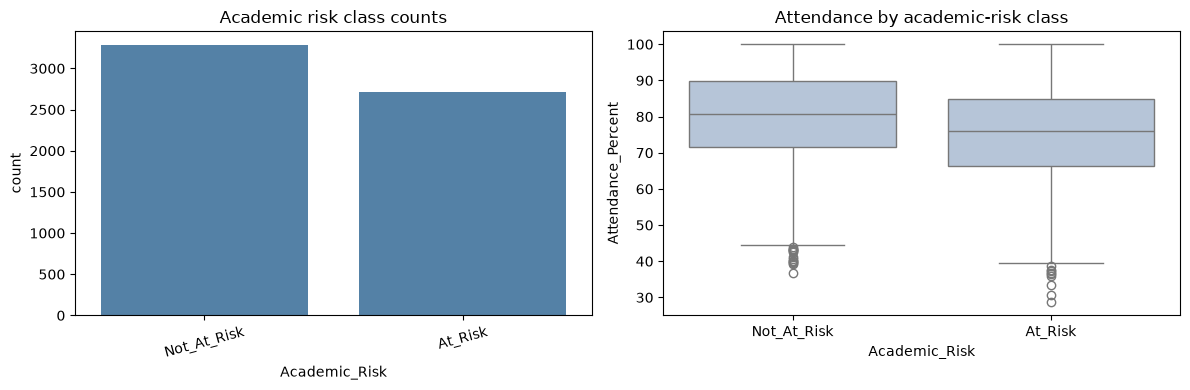

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x='Academic_Risk', color='steelblue', ax=axes[0])
axes[0].set_title('Academic risk class counts')
axes[0].tick_params(axis='x', rotation=15)
sns.boxplot(data=df, x='Academic_Risk', y='Attendance_Percent', color='lightsteelblue', ax=axes[1])
axes[1].set_title('Attendance by academic-risk class')
plt.tight_layout()
plt.show()


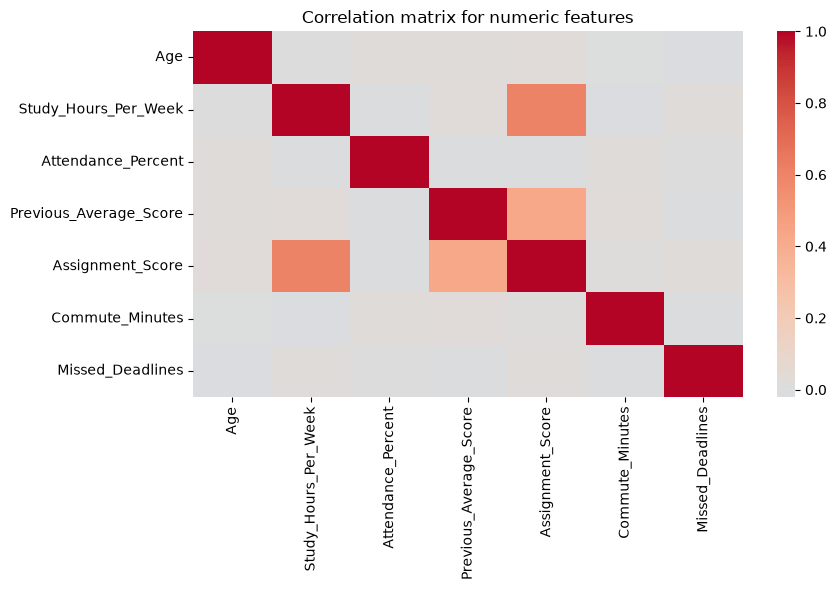

In [6]:
numeric_for_corr = df.select_dtypes(include=np.number)
plt.figure(figsize=(9, 6))
sns.heatmap(numeric_for_corr.corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Correlation matrix for numeric features')
plt.tight_layout()
plt.show()


## 4. Prepare features and target
This is a **supervised classification** task: input features (`X`) are used to predict the categorical target (`y`). A stratified hold-out test set is reserved for final evaluation. Cross-validation and all preprocessing/model selection use only the training portion.

In [7]:
TARGET = 'Academic_Risk'
DROP_COLUMNS = ['Student_ID', TARGET]
X = df.drop(columns=DROP_COLUMNS)
y = df[TARGET].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()
print('Training rows:', len(X_train), '| Test rows:', len(X_test))
print('Numeric features:', numeric_features)
print('Categorical features:', categorical_features)


Training rows: 4803 | Test rows: 1201
Numeric features: ['Age', 'Study_Hours_Per_Week', 'Attendance_Percent', 'Previous_Average_Score', 'Assignment_Score', 'Commute_Minutes', 'Missed_Deadlines']
Categorical features: ['Gender', 'Program', 'Internet_Access', 'Part_Time_Work', 'Financial_Stress']


## 5. Preprocessing and model definitions
Numeric missing values are filled with the median and standardized (z-score). Categorical missing values are filled with the most frequent category and encoded with one-hot encoding. Using a `Pipeline` and `ColumnTransformer` means these transformations are fitted only on each training fold, reducing data leakage.

In [8]:
def make_preprocessor():
    numeric_pipe = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    categorical_pipe = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])
    return ColumnTransformer(transformers=[
        ('numeric', numeric_pipe, numeric_features),
        ('categorical', categorical_pipe, categorical_features)
    ])

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=150, min_samples_leaf=3, class_weight='balanced_subsample',
                                            n_jobs=-1, random_state=RANDOM_STATE)
}


## 6. Five-fold stratified cross-validation
Each model is evaluated on five different folds. Accuracy, precision, recall, and F1-score are reported as mean and standard deviation. F1 is used as the primary comparison metric because accuracy alone can hide weak performance on one class. Stratification preserves the approximate class ratio in each fold.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'accuracy': 'accuracy', 'precision': 'precision_macro', 'recall': 'recall_macro', 'f1': 'f1_macro'}
cv_rows = []

for name, estimator in models.items():
    pipe = Pipeline(steps=[('preprocess', make_preprocessor()), ('model', estimator)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1, return_train_score=False)
    row = {'Model': name}
    for metric in scoring:
        row[f'{metric}_mean'] = scores[f'test_{metric}'].mean()
        row[f'{metric}_std'] = scores[f'test_{metric}'].std()
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).sort_values('f1_mean', ascending=False).reset_index(drop=True)
display(cv_results.round(4))


,Model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
0,Logistic Regression,0.6610,0.0061,0.6596,0.0069,0.6606,0.0073,0.6594,0.0068
1,Random Forest,0.6481,0.0058,0.6446,0.0057,0.6434,0.0054,0.6437,0.0055
2,Decision Tree,0.5948,0.0082,0.5913,0.0095,0.5908,0.0101,0.5904,0.0098


## 7. Select the best model and evaluate on the held-out test set
The model with the highest mean 5-fold macro F1-score is selected. It is then fitted on the full training split and evaluated once on the test split, which was not used during cross-validation.

In [10]:
best_name = cv_results.loc[0, 'Model']
best_pipeline = Pipeline(steps=[('preprocess', make_preprocessor()), ('model', models[best_name])])
best_pipeline.fit(X_train, y_train)
y_pred = best_pipeline.predict(X_test)

print('Best model by mean CV macro F1:', best_name)
print('\nHeld-out test metrics:')
print(f'Accuracy:  {accuracy_score(y_test, y_pred):.4f}')
print(f'Precision (macro): {precision_score(y_test, y_pred, average="macro", zero_division=0):.4f}')
print(f'Recall (macro):    {recall_score(y_test, y_pred, average="macro", zero_division=0):.4f}')
print(f'F1-score (macro):  {f1_score(y_test, y_pred, average="macro", zero_division=0):.4f}')
print('\nClassification report:')
print(classification_report(y_test, y_pred, zero_division=0))


Best model by mean CV macro F1: Logistic Regression

Held-out test metrics:
Accuracy:  0.6894
Precision (macro): 0.6871
Recall (macro):    0.6878
F1-score (macro):  0.6873

Classification report:
              precision    recall  f1-score   support

     At_Risk       0.65      0.67      0.66       544
 Not_At_Risk       0.72      0.70      0.71       657

    accuracy                           0.69      1201
   macro avg       0.69      0.69      0.69      1201
weighted avg       0.69      0.69      0.69      1201



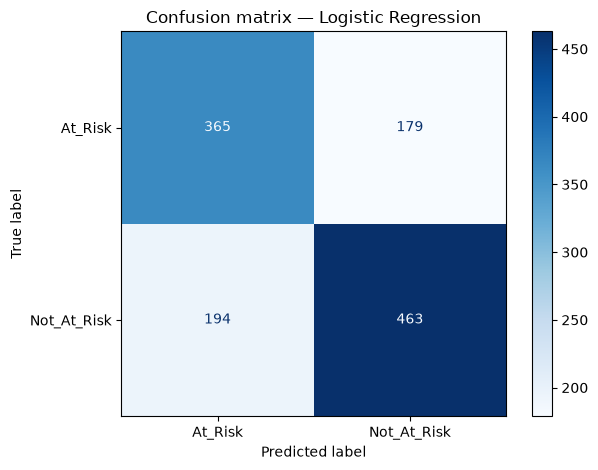

In [11]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
display.plot(cmap='Blues', values_format='d')
plt.title(f'Confusion matrix — {best_name}')
plt.tight_layout()
plt.show()


## 8. Compare cross-validation results visually
The chart displays average macro F1 across folds. Error bars show one standard deviation across folds; they indicate fold-to-fold variation, not a formal confidence interval.

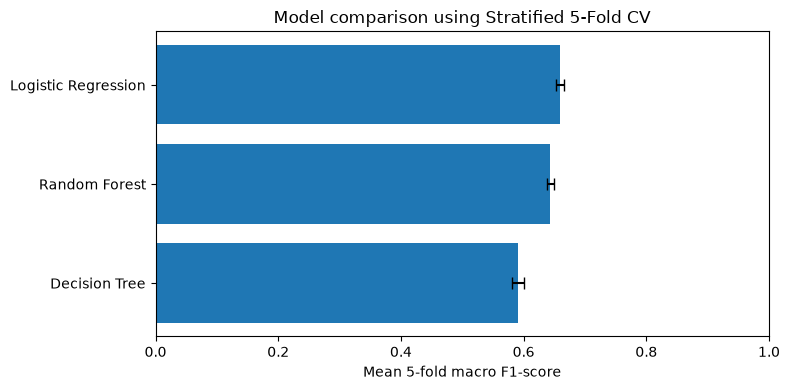

In [12]:
plot_df = cv_results.sort_values('f1_mean')
plt.figure(figsize=(8, 4))
plt.barh(plot_df['Model'], plot_df['f1_mean'], xerr=plot_df['f1_std'], capsize=4)
plt.xlabel('Mean 5-fold macro F1-score')
plt.title('Model comparison using Stratified 5-Fold CV')
plt.xlim(0, 1)
plt.tight_layout()
plt.show()


## 9. Interpretation and conclusion
- **Accuracy** is the fraction of all predictions that are correct.
- **Precision** measures how often predictions for a class are correct.
- **Recall** measures how many actual members of a class are found.
- **Macro F1** averages F1 across classes equally, making it useful when class sizes differ.
- **K-Fold Cross-Validation** rotates which part of the training data is used for validation. With 5 folds, each observation is used for validation once and for training in the other four folds.
- The highest mean CV macro F1 identifies the model selected in this experiment. Check its held-out test scores before drawing conclusions.

**Important limitation:** This is a synthetic educational dataset, not validated real student data. High scores would show that the models learned patterns built into the synthetic data; they do not prove the model can identify at-risk students in a real institution. Real deployment would require ethically collected data, privacy safeguards, fairness checks, and external validation.

In [13]:
# Optional: save cross-validation results for your report.
cv_results.to_csv('cross_validation_model_comparison.csv', index=False)
print('Saved: cross_validation_model_comparison.csv')


Saved: cross_validation_model_comparison.csv
